# 07 · (Optional extension) A/B test analysis — **SIMULATED data**
> ⚠️ **The data in this notebook is synthetic.** Olist data is observational, not a randomized experiment; nothing here is a finding about Olist. This notebook demonstrates the *method* of analysing a conversion A/B test.

**Scenario.** Test a *free-shipping banner* (treatment) vs current checkout (control).
- Randomisation unit: visitor. Metric: checkout conversion rate.
- H₀: p_treatment = p_control · H₁: p_treatment ≠ p_control (two-sided, α = 0.05).
- Minimum effect worth acting on (practical significance): **+0.5 percentage points**.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import olist
olist.setup_plots()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

## 1 · Plan the sample size before looking at data

In [2]:
p0, mde = 0.040, 0.005
es = proportion_effectsize(p0 + mde, p0)
n_req = NormalIndPower().solve_power(es, alpha=.05, power=.80, ratio=1)
print(f"Baseline conversion {p0:.1%}; to detect +{mde*100:.1f}pp with 80% power at alpha=5% we need about {int(np.ceil(n_req)):,} visitors PER ARM")

Baseline conversion 4.0%; to detect +0.5pp with 80% power at alpha=5% we need about 25,531 visitors PER ARM


## 2 · Simulate the experiment (fixed seed)

In [3]:
rng = np.random.default_rng(2024)
n_c = n_t = 20_000
true_c, true_t = 0.040, 0.0455          # known only because we are simulating
conv_c = rng.binomial(1, true_c, n_c); conv_t = rng.binomial(1, true_t, n_t)
sim = pd.DataFrame({"arm": ["control"]*n_c + ["treatment"]*n_t, "converted": np.r_[conv_c, conv_t]})
sim.groupby("arm").converted.agg(["size","sum","mean"])

,size,sum,mean
arm,,,
control,20000,790,0.04
treatment,20000,869,0.04


## 3 · Validity check — sample-ratio mismatch (SRM)

In [4]:
chi = stats.chisquare([n_c, n_t], f_exp=[(n_c+n_t)/2]*2)
print(f"SRM chi-square p = {chi.pvalue:.3f} -> {'PROBLEM: investigate randomisation' if chi.pvalue < .001 else 'allocation consistent with 50/50'}")

SRM chi-square p = 1.000 -> allocation consistent with 50/50


## 4 · Analysis

In [5]:
x = np.array([conv_t.sum(), conv_c.sum()]); n = np.array([n_t, n_c])
z, p = proportions_ztest(x, n, alternative="two-sided")
diff = x[0]/n[0] - x[1]/n[1]
lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1], compare="diff", method="wald")
print(f"control {x[1]/n[1]:.2%} | treatment {x[0]/n[0]:.2%} | absolute lift {diff*100:+.2f}pp | relative lift {diff/(x[1]/n[1]):+.1%}")
print(f"two-proportion z = {z:.2f}, p = {p:.4f}")
print(f"95% CI for difference: [{lo*100:+.2f}pp, {hi*100:+.2f}pp]")
print(f"Lower CI bound {'>=' if lo*100 >= 0.5 else '<'} the +0.5pp practical threshold")

control 3.95% | treatment 4.35% | absolute lift +0.40pp | relative lift +10.0%
two-proportion z = 1.98, p = 0.0476
95% CI for difference: [+0.00pp, +0.79pp]
Lower CI bound < the +0.5pp practical threshold


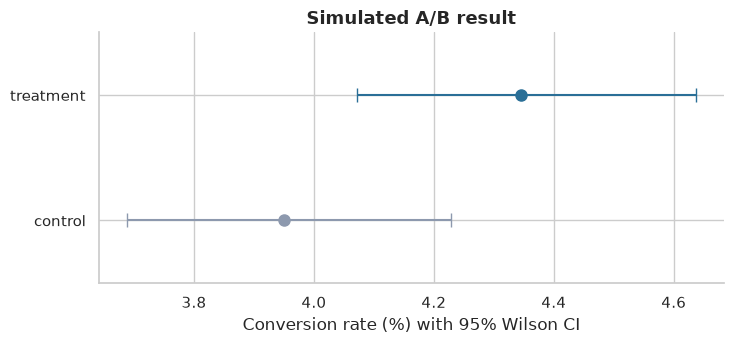

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (xi, ni, col) in enumerate([(x[1], n[1], "#8d99ae"), (x[0], n[0], "#2a6f97")]):
    lo_, hi_ = proportion_confint(xi, ni, method="wilson"); ax.errorbar(xi/ni*100, i, xerr=[[xi/ni*100-lo_*100],[hi_*100-xi/ni*100]], fmt="o", color=col, capsize=5, ms=8)
ax.set_yticks([0,1]); ax.set_yticklabels(["control","treatment"]); ax.set_xlabel("Conversion rate (%) with 95% Wilson CI"); ax.set_title("Simulated A/B result"); ax.set_ylim(-.5, 1.5)
plt.tight_layout(); olist.save_fig(fig, "20_ab_test_simulated.png")

## 5 · Interpretation checklist
- **Statistical** significance: p-value and CI above. **Practical** significance: compare the CI to the pre-set +0.5pp threshold *and* to the cost (free shipping costs margin).
- Don't peek and stop early when p < 0.05 — fix the sample size up front (step 1).
- Check guardrail metrics (AOV, margin, returns) before shipping.
- This was **simulated**: the true effect (4.0% → 4.55%) was chosen by us.

## 6 · What this particular run teaches
The run used 20,000 visitors per arm — **below** the ≈25.5k per arm the power calculation asked for. The result is borderline: lift +0.40pp, p = 0.048, CI lower bound ≈ 0. It is *statistically* significant but *not clearly* above the +0.5pp practical threshold. The honest call is "promising, under-powered: extend the test to the planned sample size" rather than "ship it". Running to the pre-planned sample size is what protects against fooling ourselves.